In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
df = sns.load_dataset('iris')
feature_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

X = StandardScaler().fit_transform(df[feature_cols])

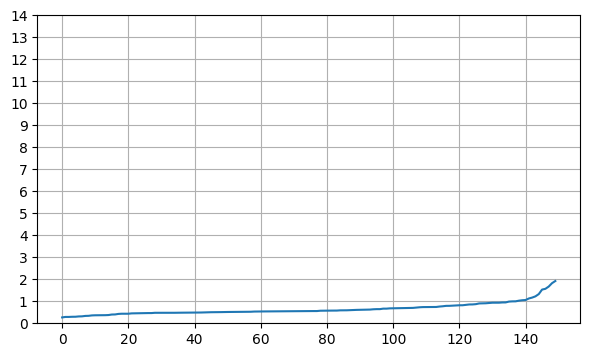

In [12]:
k = 2 * X.shape[1]
dist, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
k_dist = np.sort(dist[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(k_dist)
ax = plt.gca()
ax.set_yticks(np.arange(0, 15))
plt.grid(True)
plt.show()


In [13]:
dbscan = DBSCAN(eps=0.6, min_samples=k).fit(X)
labels_db = dbscan.labels_
print('Кластеров:', len(set(labels_db)) - (1 if -1 in labels_db else 0))
print('Доля шума:', (labels_db == -1).mean())

Кластеров: 2
Доля шума: 0.21333333333333335


In [14]:
from sklearn.mixture import GaussianMixture

bic = []
for k in range(2, 9):
    gmm_k = GaussianMixture(n_components=k, random_state=1).fit(X)
    bic.append(gmm_k.bic(X))
best_k = range(2, 9)[int(np.argmin(bic))]
gmm = GaussianMixture(n_components=best_k, random_state=1).fit(X)
labels_gmm = gmm.predict(X)
proba_gmm = gmm.predict_proba(X)


In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans = KMeans(n_clusters=best_k, random_state=1, n_init=10).fit(X)
labels_km = kmeans.labels_

mask = labels_db != -1
sil_db = silhouette_score(X[mask], labels_db[mask]) if mask.sum() > 1 else np.nan
sil_gmm = silhouette_score(X, labels_gmm)
sil_km = silhouette_score(X, labels_km)


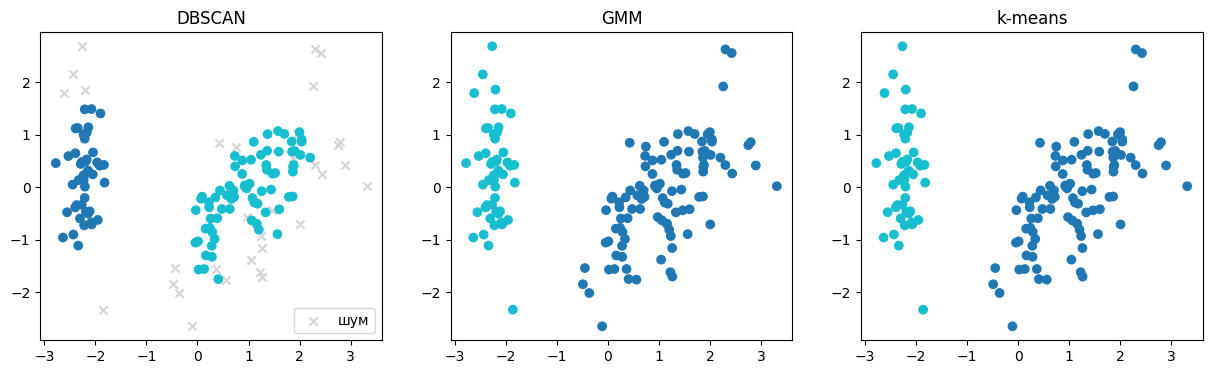

In [16]:
from sklearn.decomposition import PCA
X_pca = PCA(n_components=2).fit_transform(X)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(X_pca[~mask, 0], X_pca[~mask, 1], c='lightgray', marker='x', label='шум')
ax[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=labels_db[mask], cmap='tab10')
ax[0].set_title('DBSCAN'); ax[0].legend()
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap='tab10'); ax[1].set_title('GMM')
ax[2].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap='tab10'); ax[2].set_title('k-means')
plt.show()

Компонент для 90% дисперсии: 2


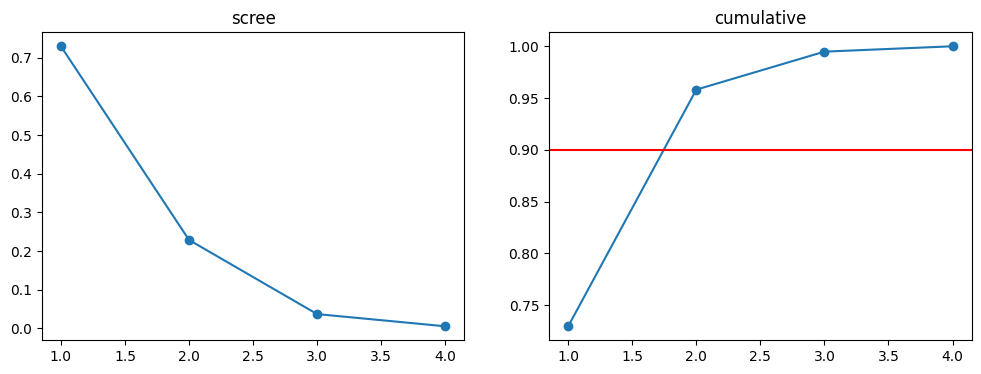

In [17]:
pca = PCA().fit(X)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_90 = int(np.argmax(cumulative >= 0.90) + 1)
print('Компонент для 90% дисперсии:', n_90)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(explained)+1), explained, 'o-'); ax[0].set_title('scree')
ax[1].plot(range(1, len(cumulative)+1), cumulative, 'o-'); ax[1].axhline(0.9, color='r'); ax[1].set_title('cumulative')
plt.show()

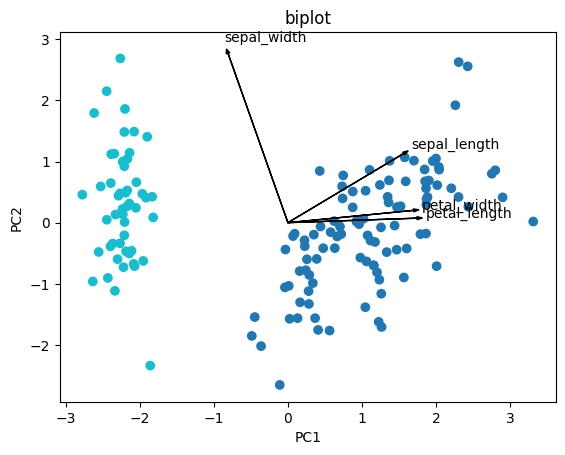

In [18]:
X_pca = pca.transform(X)[:, :2]
loadings = pca.components_[:2].T

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap='tab10')
for i, f in enumerate(feature_cols):
    plt.arrow(0, 0, loadings[i, 0]*3, loadings[i, 1]*3, color='k', head_width=0.05)
    plt.text(loadings[i, 0]*3.2, loadings[i, 1]*3.2, f)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('biplot'); plt.show()

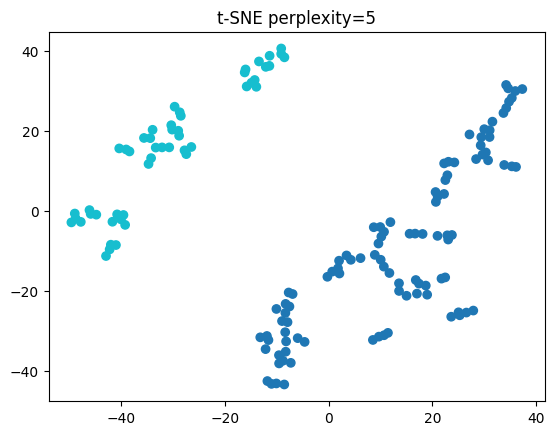

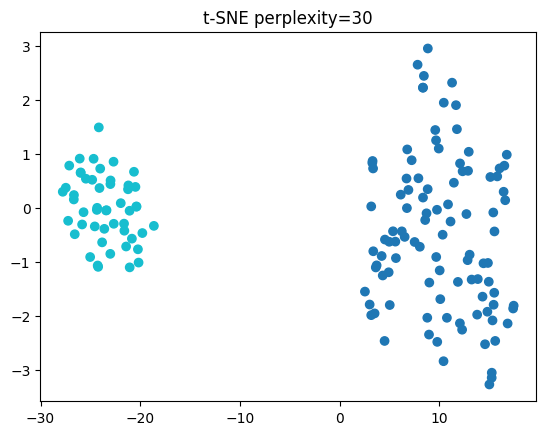

In [19]:
from sklearn.manifold import TSNE

for perp in [5, 30]:
    X_tsne = TSNE(n_components=2, perplexity=perp, random_state=22).fit_transform(X)
    plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_gmm, cmap='tab10')
    plt.title(f't-SNE perplexity={perp}'); plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


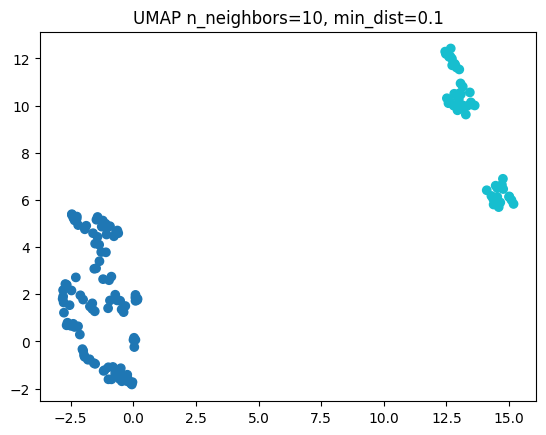

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


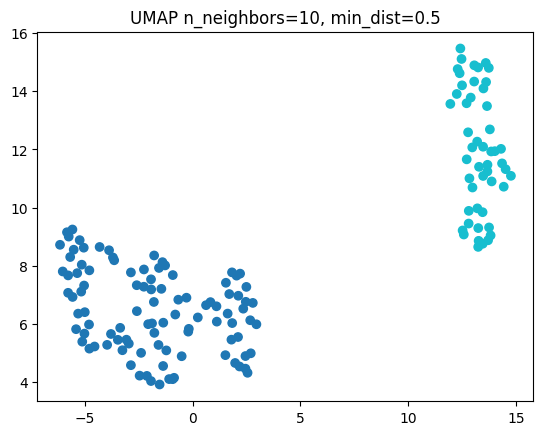

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


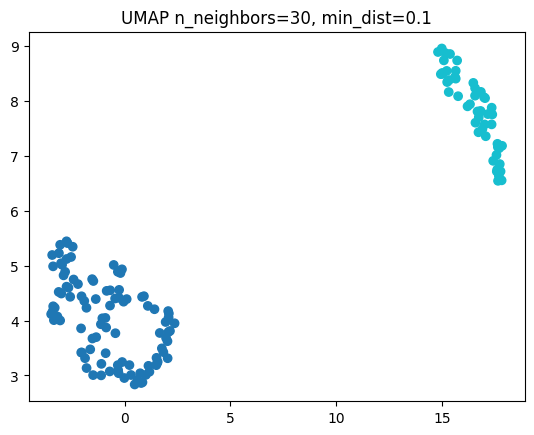

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


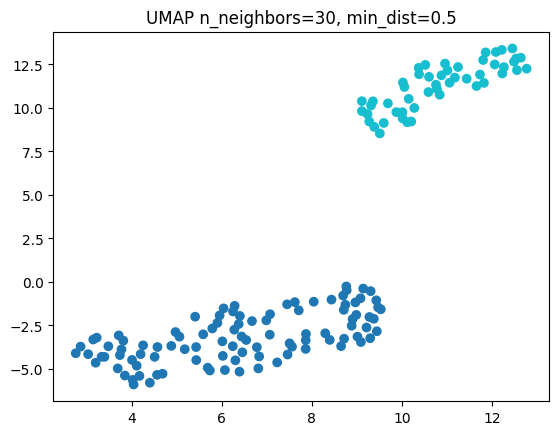

In [20]:
import umap
for nn_, md_ in [(10, 0.1), (10, 0.5), (30, 0.1), (30, 0.5)]:
    X_umap = umap.UMAP(n_neighbors=nn_, min_dist=md_, random_state=22).fit_transform(X)
    plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels_gmm, cmap='tab10')
    plt.title(f'UMAP n_neighbors={nn_}, min_dist={md_}'); plt.show()